In [2]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os

In [3]:
df = pd.read_csv(r"E:\MLOps\MMT\Data\Raw\marketing_sample_for_makemytrip_com-travel__20190901_20190930__30k_data.csv",on_bad_lines = "skip")

In [4]:
columns = df.columns.tolist()
print(f"Your Dataset Has These coulmns {columns}")

Your Dataset Has These coulmns ['Uniq Id', 'Crawl Timestamp', 'Package Name', 'Page Url', 'Package Type', 'Company', 'Destination', 'Itinerary', 'Places Covered', 'Travel Date', 'Hotel Details', 'Start City', 'Airline', 'Flight Stops', 'Onwards Return Flight Time', 'Meals', 'Price Per Two Persons', 'Per Person Price', 'Sightseeing Places Covered', 'Initial Payment For Booking', 'Cancellation Rules', 'Date Change Rules']


In [5]:
#As per our target variable which is price per person we will select out variables accordingly

In [6]:
df.describe()
#our dataset is right skewed because std is far less than mean and is around 0.58 which should Idealy be around 0.1.
#max is much higher than 75 and min is much lower than 25.
#but our dataset also has delux packages which is also important.

,Flight Stops,Meals,Price Per Two Persons,Per Person Price,Initial Payment For Booking,Date Change Rules
count,0.0,0.0,27454.000000,27454.000000,0.0,0.0
mean,NaN,NaN,39517.943688,19758.971844,NaN,NaN
std,NaN,NaN,23067.431040,11533.715520,NaN,NaN
min,NaN,NaN,1582.000000,791.000000,NaN,NaN
25%,NaN,NaN,24549.500000,12274.750000,NaN,NaN
50%,NaN,NaN,34921.500000,17460.750000,NaN,NaN
75%,NaN,NaN,49342.750000,24671.375000,NaN,NaN
max,NaN,NaN,342125.000000,171062.500000,NaN,NaN


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27454 entries, 0 to 27453
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Uniq Id                      27454 non-null  object 
 1   Crawl Timestamp              27454 non-null  object 
 2   Package Name                 27454 non-null  object 
 3   Page Url                     27454 non-null  object 
 4   Package Type                 27454 non-null  object 
 5   Company                      27454 non-null  object 
 6   Destination                  27454 non-null  object 
 7   Itinerary                    27454 non-null  object 
 8   Places Covered               27454 non-null  object 
 9   Travel Date                  27454 non-null  object 
 10  Hotel Details                23287 non-null  object 
 11  Start City                   27454 non-null  object 
 12  Airline                      21301 non-null  object 
 13  Flight Stops    

In [8]:
##travel date is an object which is wrong we need to convert it into datetime format.

In [9]:
df_null = df.isnull().sum()
print(f"Your dataset has {df_null} null values")

Your dataset has Uniq Id                            0
Crawl Timestamp                    0
Package Name                       0
Page Url                           0
Package Type                       0
Company                            0
Destination                        0
Itinerary                          0
Places Covered                     0
Travel Date                        0
Hotel Details                   4167
Start City                         0
Airline                         6153
Flight Stops                   27454
Onwards Return Flight Time      6153
Meals                          27454
Price Per Two Persons              0
Per Person Price                   0
Sightseeing Places Covered      2127
Initial Payment For Booking    27454
Cancellation Rules              1138
Date Change Rules              27454
dtype: int64 null values


In [10]:
df.duplicated().sum()

np.int64(0)

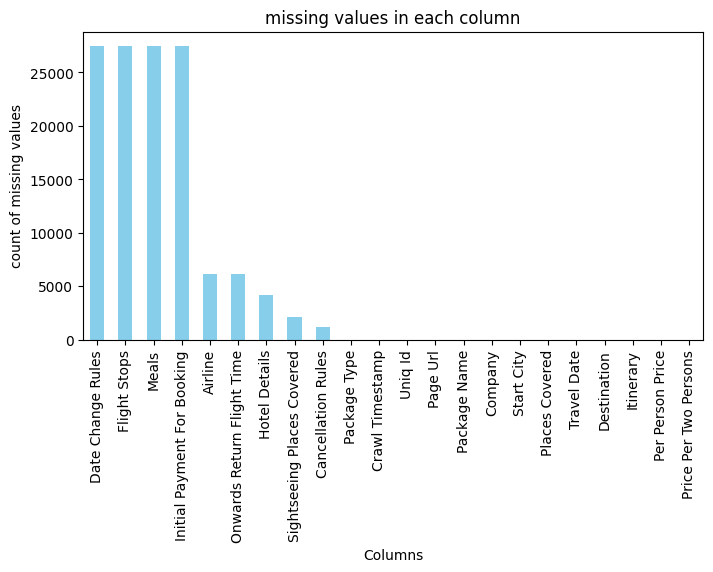

In [11]:
#Lets plot the missing values so that we could understand it better.
missing_values = df.isnull().sum()

missing_values = missing_values.sort_values(ascending=False)

plt.figure(figsize = (8,4))
missing_values.plot(kind = 'bar',color = 'skyblue')  
plt.xlabel("Columns")
plt.title ("missing values in each column")
plt.ylabel('count of missing values')
plt.xticks(rotation = 90)
plt.show()           

In [12]:
##Package Type: Potentially useful for analysis.
##Travel Date: Valuable as a numerical variable.
##Price Per Two Persons: Highly relevant, being a numerical target variable.
##Start City: Valuable due to its binary nature.

##**Not Useful Features:**

##Uniq Id: Not useful for pattern discovery.
##Crawl Timestamp: Irrelevant, representing scraping time.
##Page Url: Doesn't contribute to analysis.
##Company: Not suitable for the task.
##Destination: Contains only text data, not useful for regression.
##Itinerary: Similarly, contains textual data.
##Places Covered: Textual data.
##Hotel Details: More text data.
##Airline: Textual information.
##Onwards Return Flight Time: Limited usefulness.
##Sightseeing Places Covered: Textual data.

In [13]:
df["Per Person Price"].describe()

count     27454.000000
mean      19758.971844
std       11533.715520
min         791.000000
25%       12274.750000
50%       17460.750000
75%       24671.375000
max      171062.500000
Name: Per Person Price, dtype: float64

In [14]:
df["Per Person Price"].skew()

##0 → perfectly symmetric, 0 to ±0.5 → generally considered approximately symmetric / low skew
##±0.5 to ±1 → moderate skew,> ±1 → strong skew,< 0 → left-skewed

np.float64(2.571426356650583)

In [15]:
df["Per Person Price"].nunique()

21313

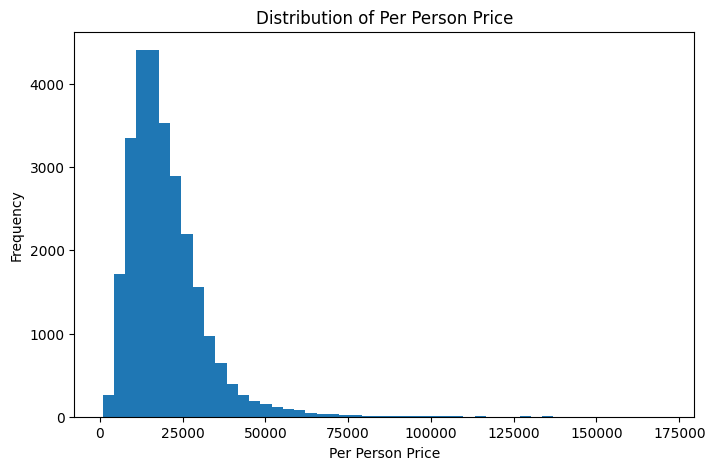

In [16]:
plt.figure(figsize=(8,5))

plt.hist(df["Per Person Price"], bins=50)

plt.title("Distribution of Per Person Price")
plt.xlabel("Per Person Price")
plt.ylabel("Frequency")

plt.show()

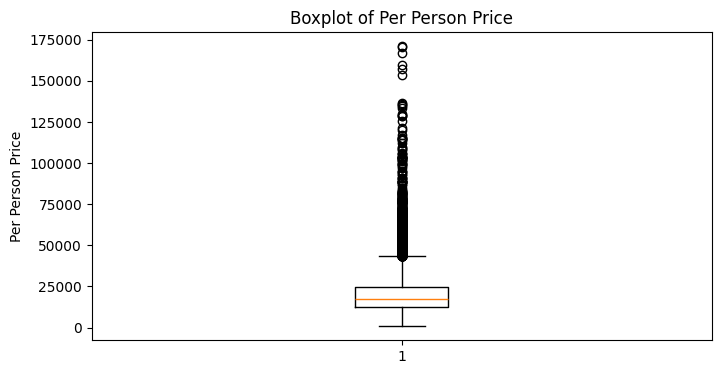

In [17]:
plt.figure(figsize=(8,4))

plt.boxplot(df["Per Person Price"])

plt.title("Boxplot of Per Person Price")
plt.ylabel("Per Person Price")

plt.show()

In [18]:
#What characteristics are associated with the high prices?
#We have additional package type which we do not need hence we will only include max occuring pckges

df.groupby("Package Type")["Per Person Price"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Package Type,,,,,
Budget,639,13600.117371,12519.50,1757.0,68407.0
Deluxe,7442,17990.076794,16222.75,1198.0,171062.5
Luxury,4065,23261.858057,21587.00,2963.0,113775.5
Premium,7025,23590.974662,21255.50,2967.0,170763.0
Standard,7196,16063.379030,14458.25,791.0,153795.0
...,...,...,...,...,...
https://holidayz.makemytrip.com/holidays/india/package?id=42186&depCityId=1218&listingClassId=2519&depDateMilliSec=1572134400000,1,27637.500000,27637.50,27637.5,27637.5
https://holidayz.makemytrip.com/holidays/india/package?id=42196&depCityId=1268&listingClassId=12&depDateMilliSec=1570492800000,1,21173.000000,21173.00,21173.0,21173.0
https://holidayz.makemytrip.com/holidays/india/package?id=42196&depCityId=1268&listingClassId=8&depDateMilliSec=1570665600000,1,19926.500000,19926.50,19926.5,19926.5


In [19]:
df["Airline"].value_counts().head(15)
#we can extract the airlines from this say person wants to use which airlines

Airline
IndiGo                                             4968
Spicejet                                           4185
Go Air                                             2721
IndiGo|IndiGo                                      1473
Spicejet|Spicejet                                  1153
Vistara                                             818
Air India                                           694
IndiGo|IndiGo|IndiGo|IndiGo                         655
IndiGo|Spicejet                                     480
Spicejet|IndiGo                                     343
Go Air|IndiGo                                       218
Vistara|Vistara                                     171
IndiGo|IndiGo|IndiGo                                156
Malindo Air|Malindo Air|Malindo Air|Malindo Air     156
Go Air|Spicejet                                     150
Name: count, dtype: int64

In [20]:
df["Destination"].value_counts().head(15)
#We can use the destination for our feature engneering

Destination
Goa                                   1301
Makemytrip                            1087
Munnar|Thekkady|Allepey                465
Shimla|Manali|Chandigarh               401
Port Blair|Havelock|Port Blair         392
Munnar                                 391
Cochin|Munnar|Thekkady|Allepey         353
Srinagar|Gulmarg|Pahalgam|Srinagar     311
Jaipur                                 311
Udaipur                                294
Gangtok|Pelling|Darjeeling             288
Ooty                                   287
Darjeeling|Gangtok                     287
Mysore|Ooty                            277
Leh                                    268
Name: count, dtype: int64

In [21]:
#binary_feature_we_have_got
df["Start City"].value_counts()

Start City
New Delhi    19664
Mumbai        7790
Name: count, dtype: int64

In [22]:
df["Itinerary"].value_counts().head(10)

Itinerary
3N Goa                                              586
3N Munnar                                           316
2N Munnar . 1N Thekkady . 1N Allepey                311
1N Cochin . 2N Munnar . 1N Thekkady . 1N Allepey    271
1N Mysore . 2N Coorg . 2N Ooty                      262
2N Goa                                              248
4N Goa                                              236
3N Jaipur                                           220
2N Udaipur                                          194
3N Ooty                                             179
Name: count, dtype: int64

In [23]:
unique_airlines = df["Airline"].nunique()
print(f"Number of unique airlines: {unique_airlines}")


Number of unique airlines: 341


In [24]:
df["Hotel_Rating"] = df["Hotel Details"].str.extract(r":(\d+\.\d+)")[0].astype(float)
#Now let's use mode to fill the missing values.
df_null = df["Hotel_Rating"].isnull().sum()
print(f"Number of missing values in the Hotel rating column : {df_null}")


Number of missing values in the Hotel rating column : 7323


In [25]:
#Fill the missing values with MODE 

df["Hotel_Rating"].mode()[0]

np.float64(4.5)

In [26]:
#now lets fill all the columns

df["Hotel_Rating"] = df["Hotel_Rating"].fillna(df["Hotel_Rating"].mode()[0])

In [27]:
df["Hotel_Rating"].describe()

count    27454.000000
mean         4.209175
std          0.407546
min          1.500000
25%          4.000000
50%          4.400000
75%          4.500000
max          5.000000
Name: Hotel_Rating, dtype: float64

In [28]:
df["Travel Date"].head(10)

0    02-10-2019
1    02-10-2019
2    24-10-2019
3    26-10-2019
4    13-10-2019
5    26-09-2019
6    30-09-2019
7    11-10-2019
8    30-09-2019
9    04-10-2019
Name: Travel Date, dtype: object

In [29]:
#As the travel date is in object we need to convert it into datetime

df["Travel Date"] = pd.to_datetime(df["Travel Date"],format = "%d-%m-%Y",errors = "coerce")

In [30]:
df.nunique()

Uniq Id                        27454
Crawl Timestamp                25974
Package Name                    2231
Page Url                       26628
Package Type                    1092
Company                            6
Destination                      566
Itinerary                       1190
Places Covered                   895
Travel Date                       55
Hotel Details                   6499
Start City                         2
Airline                          341
Flight Stops                       0
Onwards Return Flight Time      2110
Meals                              0
Price Per Two Persons          21313
Per Person Price               21313
Sightseeing Places Covered      1771
Initial Payment For Booking        0
Cancellation Rules                 8
Date Change Rules                  0
Hotel_Rating                      32
dtype: int64

In [31]:
df["Package Type"].head(20)

0                                                Deluxe
1                                              Standard
2                                                Deluxe
3                                              Standard
4                                              Standard
5                                               Premium
6                                              Standard
7                                              Standard
8                                                Deluxe
9                                               Premium
10                                               Deluxe
11                                              Premium
12                                               Luxury
13                                              Premium
14    https://holidayz.makemytrip.com/holidays/india...
15                                               Deluxe
16    https://holidayz.makemytrip.com/holidays/india...
17                                             S

In [32]:
df["Package Type"].describe()

#Delux has appread more in 7442 but we should only have 5 to 6 package types.
#wewill handle it in cleaning stage

count      27454
unique      1092
top       Deluxe
freq        7442
Name: Package Type, dtype: object

In [33]:
df["Per Person Price"].describe()

#Working on our target variable.

count     27454.000000
mean      19758.971844
std       11533.715520
min         791.000000
25%       12274.750000
50%       17460.750000
75%       24671.375000
max      171062.500000
Name: Per Person Price, dtype: float64

In [34]:
df[["Hotel_Rating", "Per Person Price"]].corr()

,Hotel_Rating,Per Person Price
Hotel_Rating,1.000000,0.067171
Per Person Price,0.067171,1.000000


In [35]:
###EDA concluded here we will now begin Cleaning 

df["Cancellation Rules"].head()

0    Cancellation any time after making the 1st pay...
1    Cancellation any time after making the 1st pay...
2    This cancellation policy is applicable for boo...
3    Cancellation any time after making the 1st pay...
4    Cancellation any time after making the 1st pay...
Name: Cancellation Rules, dtype: object